In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

,N,HPBW_deg,first_null_deg,sidelobe_dB,minimum_separation_for_10dB
0,2,60.00,90.00,NaN,52.7
1,4,26.32,30.00,-11.30,22.1
2,8,12.80,14.48,-12.80,10.7
3,16,6.34,7.18,-13.15,5.3


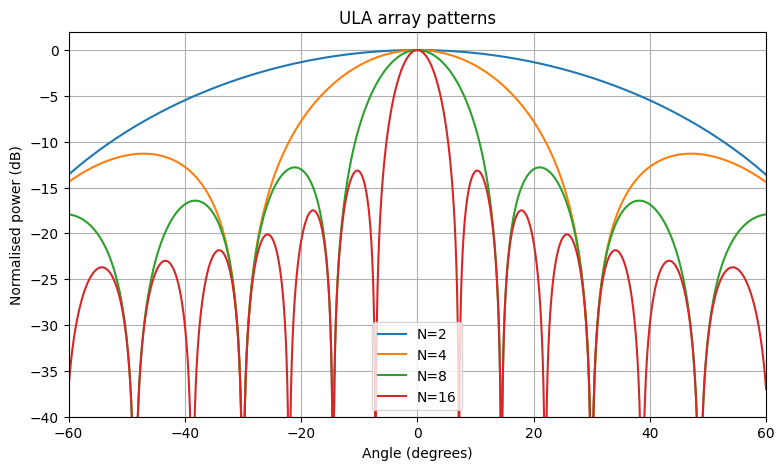

In [2]:
def array_power(N, theta_deg, steer_deg=0, d_over_lambda=0.5):
    th=np.deg2rad(theta_deg); th0=np.deg2rad(steer_deg)
    psi=2*np.pi*d_over_lambda*(np.sin(th)-np.sin(th0))
    denom=np.sin(psi/2)
    ratio=np.ones_like(np.asarray(psi,dtype=float))
    mask=np.abs(denom)>1e-12
    ratio[mask]=np.sin(N*psi[mask]/2)/(N*denom[mask])
    return np.abs(ratio)**2

angles=np.linspace(-90,90,18001)
summary=[]; sir_rows=[]
for N in (2,4,8,16):
    p=array_power(N,angles)
    p_db=10*np.log10(np.maximum(p,1e-12))
    peak=np.max(p)
    # HPBW around broadside.
    idx=np.where(p>=0.5*peak)[0]
    hpbw=angles[idx[-1]]-angles[idx[0]]
    # Side lobe outside first null (if present).
    null_angle=np.rad2deg(np.arcsin(min(1,2/N))) if N>2 else 90
    sidelobe=np.max(p_db[np.abs(angles)>null_angle+0.2]) if N>2 else np.nan
    good=[]
    for sep in np.arange(5,60.1,0.1):
        leak=float(array_power(N,np.array([sep]))[0])
        sir=-10*np.log10(max(leak,1e-15))
        sir_rows.append([N,sep,sir])
        if sir>=10: good.append(sep)
    summary.append([N,hpbw,null_angle,sidelobe,min(good) if good else np.nan])
q5_summary=pd.DataFrame(summary,columns=["N","HPBW_deg","first_null_deg","sidelobe_dB","minimum_separation_for_10dB"])
q5_sir=pd.DataFrame(sir_rows,columns=["N","separation_deg","SIR_dB"])
display(q5_summary.round(2))
q5_summary.to_csv("q5_array_summary.csv",index=False)
q5_sir.to_csv("q5_sir_vs_sep.csv",index=False)

plt.figure(figsize=(9,5))
for N in (2,4,8,16):
    plt.plot(angles,10*np.log10(np.maximum(array_power(N,angles),1e-5)),label=f"N={N}")
plt.ylim(-40,2); plt.xlim(-60,60); plt.xlabel("Angle (degrees)"); plt.ylabel("Normalised power (dB)")
plt.title("ULA array patterns"); plt.grid(True); plt.legend(); plt.show()